In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("deep")  
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = Path("hospital_inpatient_discharges_totalhipreplacement.csv")


if not DATA_PATH.exists():
    alternative = Path("/mnt/data/hospital_inpatient_discharges_totalhipreplacement.csv")
    if alternative.exists():
        DATA_PATH = alternative

print("Data file:", DATA_PATH.resolve())
print("SciPy available:", SCIPY_AVAILABLE)

Data file: C:\Users\Dell\Downloads\hospital_inpatient_discharges_totalhipreplacement.csv
SciPy available: True


## Load the data

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Rows: 26,594
Columns: 30


,health_service_area,hospital_county,operating_certificate_number,facility_id,facility_name,age_group,zip_code_3_digits,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccs_diagnosis_code,ccs_diagnosis_description,ccs_procedure_code,ccs_procedure_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness_description,apr_risk_of_mortality,apr_medical_surgical_description,attending_provider_license_number,operating_provider_license_number,total_charges,total_costs
0,Western NY,Allegany,228000,39,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,70 or Older,148,F,White,Not Span/Hispanic,6,Elective,Hosp Basd Medicare Approved Swing Bed,2016,203,Osteoarthritis,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,2,Moderate,Minor,Surgical,213053,213053,"35,681.75","17,400.79"
1,Western NY,Allegany,228000,39,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,148,F,White,Not Span/Hispanic,4,Elective,Home or Self Care,2016,203,Osteoarthritis,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,2,Moderate,Minor,Surgical,213053,213053,"34,289.25","16,657.95"
2,Western NY,Allegany,228000,39,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,147,M,White,Not Span/Hispanic,3,Elective,Home or Self Care,2016,203,Osteoarthritis,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,2,Moderate,Minor,Surgical,213053,213053,"30,436.00","14,703.62"
3,Western NY,Allegany,228000,39,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,147,M,White,Not Span/Hispanic,3,Elective,Hosp Basd Medicare Approved Swing Bed,2016,203,Osteoarthritis,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,1,Minor,Minor,Surgical,213053,213053,"28,699.00","13,903.30"
4,Western NY,Allegany,228000,39,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,148,M,White,Not Span/Hispanic,2,Elective,Home or Self Care,2016,237,Complication of device; implant or graft,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,1,Minor,Minor,Surgical,213053,213053,"18,421.00","8,258.43"


## Data dictionary and initial profiling

In [3]:
data_dictionary = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "non_null_count": [df[c].notna().sum() for c in df.columns],
    "missing_count": [df[c].isna().sum() for c in df.columns],
    "distinct_values": [df[c].nunique(dropna=True) for c in df.columns]
})
display(data_dictionary)

,column,dtype,non_null_count,missing_count,distinct_values
0,health_service_area,object,26594,0,8
1,hospital_county,object,26594,0,49
2,operating_certificate_number,int64,26594,0,132
3,facility_id,int64,26594,0,151
4,facility_name,object,26594,0,151
5,age_group,object,26594,0,5
6,zip_code_3_digits,object,26574,20,50
7,gender,object,26594,0,2
8,race,object,26594,0,4
9,ethnicity,object,26594,0,4


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
health_service_area,26594,8,New York City,10084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hospital_county,26594,49,Manhattan,8250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operating_certificate_number,"26,594.00",NaN,NaN,NaN,"4,460,324.64","2,394,597.67","101,000.00","2,701,003.00","4,601,001.00","7,002,012.00","7,004,010.00"
facility_id,"26,594.00",NaN,NaN,NaN,903.07,583.96,1.00,411.00,829.00,"1,447.00","3,376.00"
facility_name,26594,151,Hospital for Special Surgery,4520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,26594,5,50 to 69,15479,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip_code_3_digits,26574,50,117,2457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,26594,2,F,14282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,26594,4,White,21853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ethnicity,26594,4,Not Span/Hispanic,24764,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

profile = pd.DataFrame({
    "metric": [
        "Discharge records",
        "Distinct hospitals",
        "Distinct counties",
        "Distinct discharge years",
        "Minimum discharge year",
        "Maximum discharge year",
        "APR-DRG 301 records",
        "CCS procedure 153 records"
    ],
    "value": [
        len(df),
        df["facility_id"].nunique(),
        df["hospital_county"].nunique(),
        df["discharge_year"].nunique(),
        df["discharge_year"].min(),
        df["discharge_year"].max(),
        (df["apr_drg_code"] == 301).sum(),
        (df["ccs_procedure_code"] == 153).sum()
    ]
})
display(profile)
display(df["ccs_procedure_description"].value_counts(dropna=False).to_frame("records"))

,metric,value
0,Discharge records,26594
1,Distinct hospitals,151
2,Distinct counties,49
3,Distinct discharge years,1
4,Minimum discharge year,2016
5,Maximum discharge year,2016
6,APR-DRG 301 records,26594
7,CCS procedure 153 records,26286


,records
ccs_procedure_description,
"HIP REPLACEMENT,TOT/PRT",26286
OT OR THER PRC ON JOINT,230
BLOOD TRANSFUSION,26
OT OR THER PRCS ON BONE,8
OTHER THERAPEUTIC PRCS,5
OT DX PRCS ON MUSC/SKEL,5
OT NON-OR THER PRC MUSC,5
"TRTMNT,FRAC HIP/FEMUR",4
OT OR THER PRC SKN/BRST,4


## Data quality assessment

In [6]:
missing = (
    df.isna().sum()
      .rename("missing_values")
      .to_frame()
      .assign(missing_pct=lambda x: (x["missing_values"] / len(df) * 100).round(2))
      .sort_values("missing_values", ascending=False)
)
display(missing[missing["missing_values"] > 0])

print("Exact duplicate rows:", df.duplicated().sum())
print("Negative LOS records:", (df["length_of_stay"] < 0).sum())
print("Negative charge records:", (df["total_charges"] < 0).sum())
print("Negative cost records:", (df["total_costs"] < 0).sum())
print("Missing facility IDs:", df["facility_id"].isna().sum())

,missing_values,missing_pct
zip_code_3_digits,20,0.08


Exact duplicate rows: 8
Negative LOS records: 0
Negative charge records: 0
Negative cost records: 0
Missing facility IDs: 0


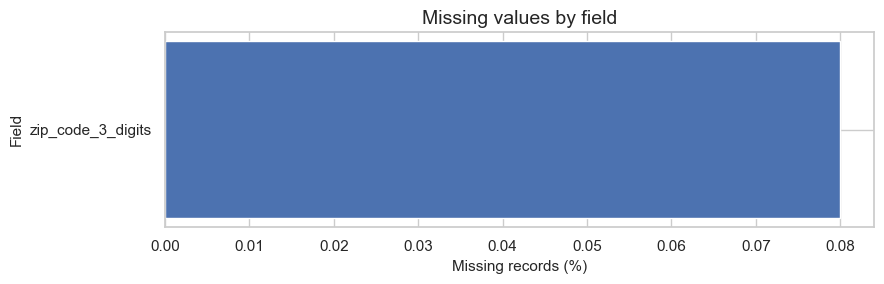

In [7]:

missing_plot = missing[missing["missing_values"] > 0].sort_values("missing_pct")
if len(missing_plot):
    fig, ax = plt.subplots(figsize=(9, max(3, len(missing_plot) * 0.35)))
    ax.barh(missing_plot.index.astype(str), missing_plot["missing_pct"])
    ax.set(title="Missing values by field", xlabel="Missing records (%)", ylabel="Field")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

## Define the analytical cohort

The full source file contains APR-DRG 301 records. The primary analysis cohort is restricted to CCS procedure code 153 (`HIP REPLACEMENT,TOT/PRT`).

In [8]:
drg_cohort = df.loc[df["apr_drg_code"] == 301].copy()
hip_cohort = drg_cohort.loc[drg_cohort["ccs_procedure_code"] == 153].copy()

print(f"APR-DRG 301 records: {len(drg_cohort):,}")
print(f"CCS 153 total/partial hip replacement records: {len(hip_cohort):,}")
print(f"Other procedure records within APR-DRG 301: {len(drg_cohort) - len(hip_cohort):,}")

assert len(hip_cohort) > 0, "No CCS procedure code 153 records found."

APR-DRG 301 records: 26,594
CCS 153 total/partial hip replacement records: 26,286
Other procedure records within APR-DRG 301: 308


In [9]:

hip_cohort["cost_to_charge_ratio"] = np.where(
    hip_cohort["total_charges"] > 0,
    hip_cohort["total_costs"] / hip_cohort["total_charges"],
    np.nan
)

hip_cohort["major_or_extreme_severity"] = hip_cohort[
    "apr_severity_of_illness_description"
].isin(["Major", "Extreme"])

hip_cohort["home_health_discharge"] = (
    hip_cohort["patient_disposition"] == "Home w/ Home Health Services"
)

hip_cohort["high_los_flag"] = (
    hip_cohort["length_of_stay"] > hip_cohort["length_of_stay"].quantile(0.95)
)

display(hip_cohort[[
    "facility_name", "age_group", "gender", "length_of_stay",
    "total_charges", "total_costs", "cost_to_charge_ratio",
    "patient_disposition"
]].head())

,facility_name,age_group,gender,length_of_stay,total_charges,total_costs,cost_to_charge_ratio,patient_disposition
0,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,70 or Older,F,6,"35,681.75","17,400.79",0.49,Hosp Basd Medicare Approved Swing Bed
1,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,F,4,"34,289.25","16,657.95",0.49,Home or Self Care
2,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,M,3,"30,436.00","14,703.62",0.48,Home or Self Care
3,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,M,3,"28,699.00","13,903.30",0.48,Hosp Basd Medicare Approved Swing Bed
4,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,50 to 69,M,2,"18,421.00","8,258.43",0.45,Home or Self Care


## Executive KPI summary

In [10]:
kpis = pd.Series({
    "Total discharge records": len(hip_cohort),
    "Hospitals": hip_cohort["facility_id"].nunique(),
    "Counties": hip_cohort["hospital_county"].nunique(),
    "Average LOS (days)": hip_cohort["length_of_stay"].mean(),
    "Median LOS (days)": hip_cohort["length_of_stay"].median(),
    "Average reported cost per discharge": hip_cohort["total_costs"].mean(),
    "Median reported cost per discharge": hip_cohort["total_costs"].median(),
    "Average reported charges per discharge": hip_cohort["total_charges"].mean(),
    "Aggregate reported costs": hip_cohort["total_costs"].sum(),
    "Aggregate reported charges": hip_cohort["total_charges"].sum(),
    "Home health discharge share (%)": hip_cohort["home_health_discharge"].mean() * 100,
    "Major/extreme severity share (%)": hip_cohort["major_or_extreme_severity"].mean() * 100
})
display(kpis.to_frame("value").round(2))

,value
Total discharge records,"26,286.00"
Hospitals,151.00
Counties,49.00
Average LOS (days),2.65
Median LOS (days),2.00
Average reported cost per discharge,"20,910.35"
Median reported cost per discharge,"18,588.72"
Average reported charges per discharge,"59,440.01"
Aggregate reported costs,"549,649,448.36"
Aggregate reported charges,"1,562,440,170.56"


## Procedure utilization and patient demographics

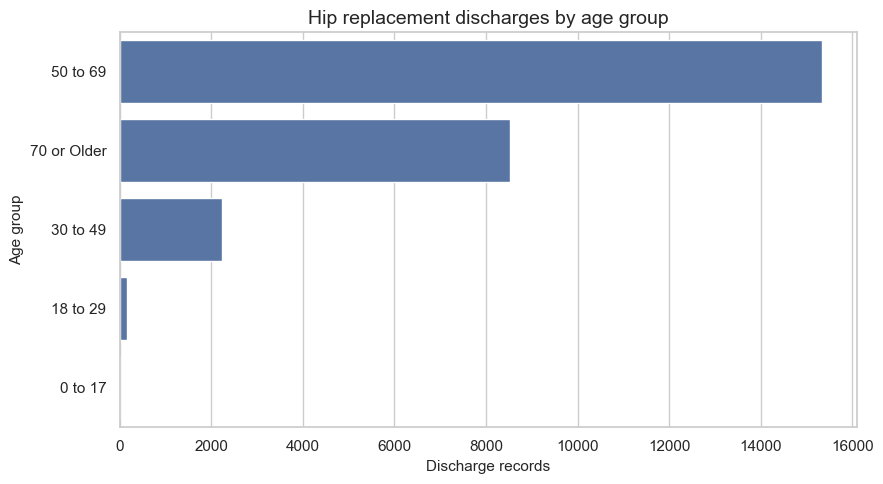

In [11]:
age_order = hip_cohort["age_group"].value_counts().index
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=hip_cohort, y="age_group", order=age_order, color="C0")
ax.set(title="Hip replacement discharges by age group", xlabel="Discharge records", ylabel="Age group")
plt.tight_layout()
plt.show()

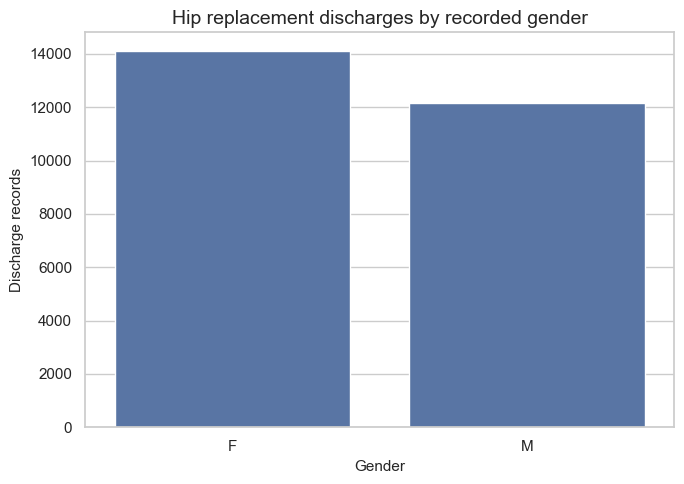

,gender,records,share_pct
0,F,14107,53.67
1,M,12179,46.33


In [12]:
gender_counts = hip_cohort["gender"].value_counts(dropna=False).rename_axis("gender").reset_index(name="records")
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=gender_counts, x="gender", y="records", color="C0")
ax.set(title="Hip replacement discharges by recorded gender", xlabel="Gender", ylabel="Discharge records")
plt.tight_layout()
plt.show()
display(gender_counts.assign(share_pct=(gender_counts["records"] / len(hip_cohort) * 100).round(2)))

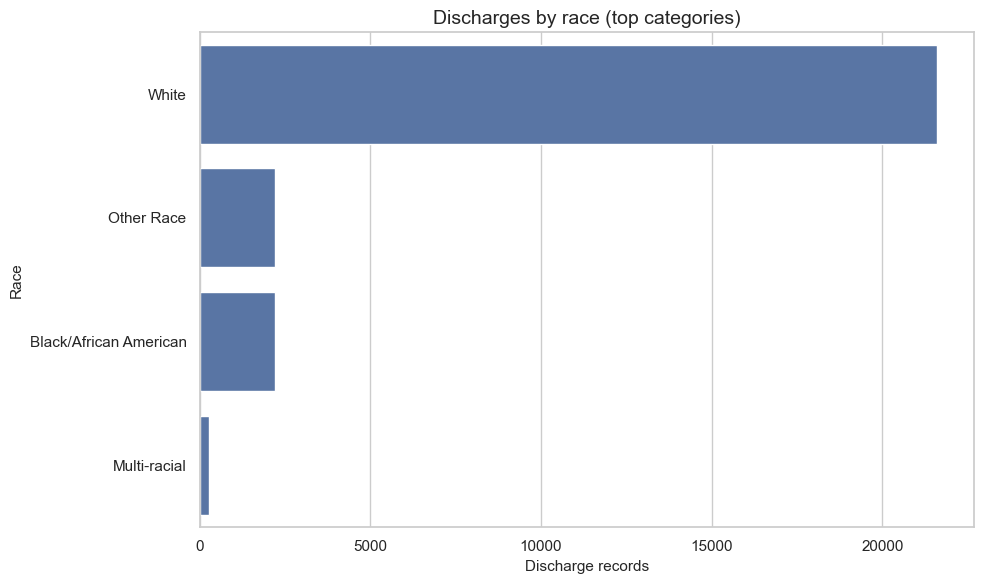

In [13]:
race_counts = hip_cohort["race"].value_counts().head(10).reset_index()
race_counts.columns = ["race", "records"]
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=race_counts, y="race", x="records", color="C0")
ax.set(title="Discharges by race (top categories)", xlabel="Discharge records", ylabel="Race")
plt.tight_layout()
plt.show()

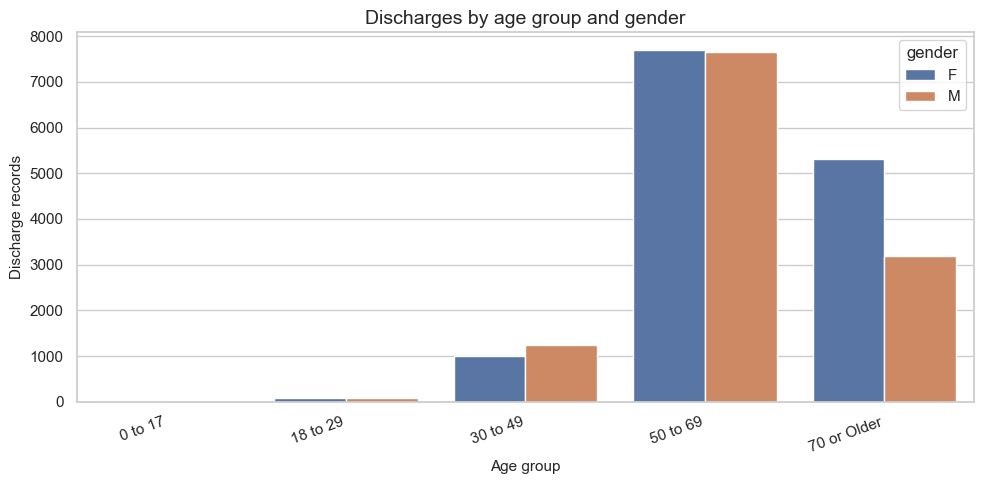

In [14]:
age_gender = (
    hip_cohort.groupby(["age_group", "gender"])
    .size().reset_index(name="records")
)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=age_gender, x="age_group", y="records", hue="gender", palette="deep")
ax.set(title="Discharges by age group and gender", xlabel="Age group", ylabel="Discharge records")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Interpretation guidance

## Geographic and hospital utilization

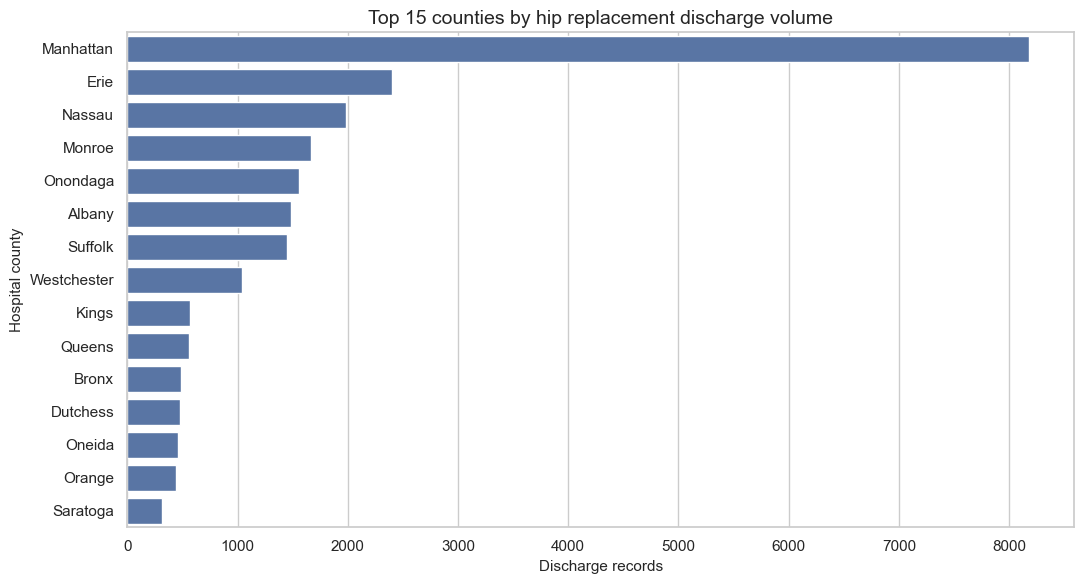

,hospital_county,discharges
0,Manhattan,8180
1,Erie,2399
2,Nassau,1984
3,Monroe,1668
4,Onondaga,1560
5,Albany,1482
6,Suffolk,1444
7,Westchester,1044
8,Kings,564
9,Queens,561


In [15]:

county_volume = (
    hip_cohort.groupby("hospital_county").size()
    .sort_values(ascending=False).head(15)
    .rename("discharges").reset_index()
)
plt.figure(figsize=(11, 6))
ax = sns.barplot(data=county_volume, y="hospital_county", x="discharges", color="C0")
ax.set(title="Top 15 counties by hip replacement discharge volume", xlabel="Discharge records", ylabel="Hospital county")
plt.tight_layout()
plt.show()
display(county_volume)

,facility_id,facility_name,hospital_county,discharges
128,1447,Hospital for Special Surgery,Manhattan,4515
127,1446,NYU Hospital for Joint Diseases,Manhattan,1761
1,5,St Peters Hospital,Albany,912
19,207,Buffalo General Hospital,Erie,776
34,409,Highland Hospital,Monroe,762
57,630,St Josephs Hospital Health Center,Onondaga,731
129,1450,Lenox Hill Hospital,Manhattan,594
59,636,Crouse Hospital,Onondaga,577
37,471,The Unity Hospital of Rochester,Monroe,574
0,1,Albany Medical Center Hospital,Albany,570


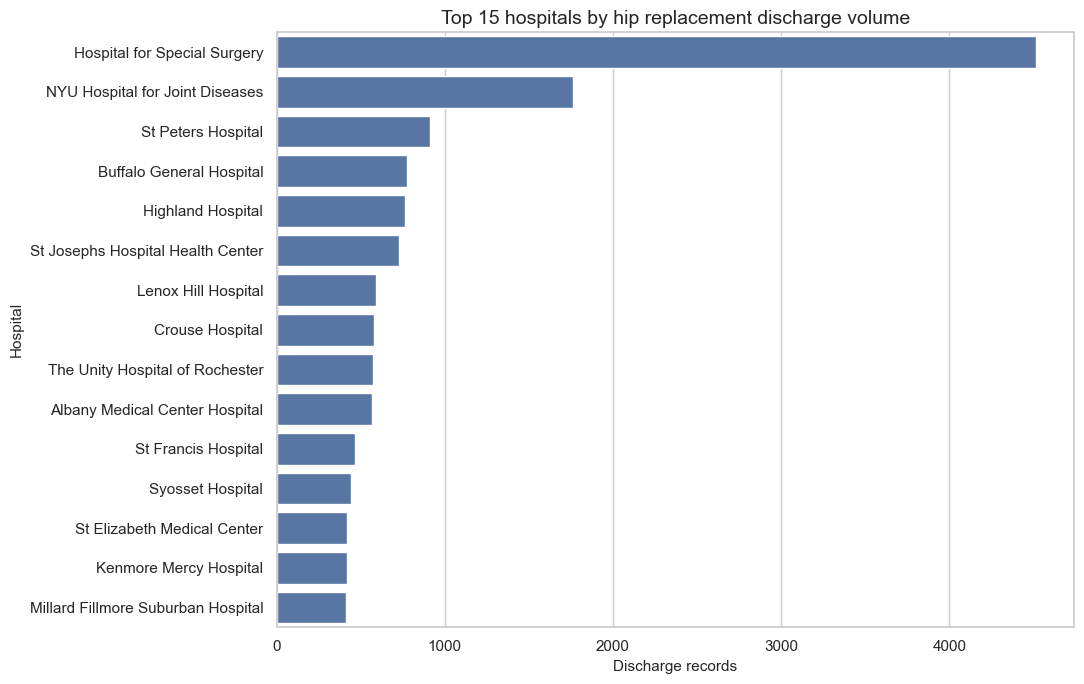

In [16]:

hospital_volume = (
    hip_cohort.groupby(["facility_id", "facility_name", "hospital_county"])
    .size().reset_index(name="discharges")
    .sort_values("discharges", ascending=False)
)
display(hospital_volume.head(15))
plt.figure(figsize=(11, 7))
ax = sns.barplot(data=hospital_volume.head(15), y="facility_name", x="discharges", color="C0")
ax.set(title="Top 15 hospitals by hip replacement discharge volume", xlabel="Discharge records", ylabel="Hospital")
plt.tight_layout()
plt.show()

In [17]:
hospital_metrics = (
    hip_cohort.groupby(["facility_id", "facility_name", "hospital_county"])
    .agg(
        discharges=("facility_id", "size"),
        avg_los=("length_of_stay", "mean"),
        median_los=("length_of_stay", "median"),
        avg_cost=("total_costs", "mean"),
        median_cost=("total_costs", "median"),
        avg_charges=("total_charges", "mean"),
        cost_sum=("total_costs", "sum")
    )
    .reset_index()
)
hospital_metrics["cost_to_charge_ratio"] = (
    hospital_metrics["cost_sum"] /
    hip_cohort.groupby("facility_id")["total_charges"].sum().reindex(hospital_metrics["facility_id"]).to_numpy()
)
display(hospital_metrics.query("discharges >= 30").sort_values("discharges", ascending=False).head(20))

,facility_id,facility_name,hospital_county,discharges,avg_los,median_los,avg_cost,median_cost,avg_charges,cost_sum,cost_to_charge_ratio
128,1447,Hospital for Special Surgery,Manhattan,4515,2.65,2.00,"23,859.30","22,357.50","67,892.06","107,724,760.81",0.35
127,1446,NYU Hospital for Joint Diseases,Manhattan,1761,2.17,2.00,"28,385.90","25,316.86","126,681.21","49,987,574.48",0.22
1,5,St Peters Hospital,Albany,912,1.98,2.00,"12,105.15","11,346.95","31,678.35","11,039,896.17",0.38
19,207,Buffalo General Hospital,Erie,776,2.14,2.00,"15,034.31","13,669.17","40,193.60","11,666,627.61",0.37
34,409,Highland Hospital,Monroe,762,2.18,2.00,"11,175.08","10,365.01","25,960.09","8,515,408.78",0.43
57,630,St Josephs Hospital Health Center,Onondaga,731,2.73,2.00,"12,034.99","11,520.72","34,561.52","8,797,581.25",0.35
129,1450,Lenox Hill Hospital,Manhattan,594,2.72,2.00,"18,019.66","16,636.43","70,258.76","10,703,680.19",0.26
59,636,Crouse Hospital,Onondaga,577,2.60,2.00,"13,773.17","12,945.71","29,302.91","7,947,119.38",0.47
37,471,The Unity Hospital of Rochester,Monroe,574,1.85,2.00,"20,554.80","20,330.42","24,974.18","11,798,453.47",0.82
0,1,Albany Medical Center Hospital,Albany,570,2.14,2.00,"14,991.61","13,876.73","34,098.45","8,545,215.94",0.44


## Length of stay (LOS) analysis

LOS is a common inpatient operations metric.

In [18]:
los_summary = hip_cohort["length_of_stay"].describe(percentiles=[.25, .5, .75, .90, .95, .99]).to_frame("LOS_days")
display(los_summary)

,LOS_days
count,"26,286.00"
mean,2.65
std,2.09
min,1.00
25%,2.00
50%,2.00
75%,3.00
90%,4.00
95%,5.00
99%,9.00


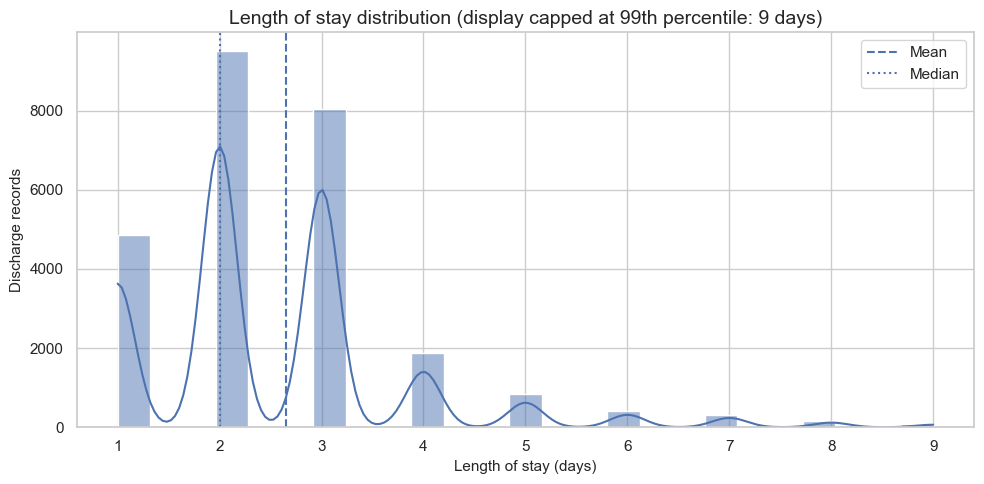

In [19]:
los_cap = hip_cohort["length_of_stay"].quantile(0.99)
plt.figure(figsize=(10, 5))
sns.histplot(hip_cohort.loc[hip_cohort["length_of_stay"] <= los_cap, "length_of_stay"],
             bins=25, kde=True, color="C0")
plt.axvline(hip_cohort["length_of_stay"].mean(), linestyle="--", label="Mean")
plt.axvline(hip_cohort["length_of_stay"].median(), linestyle=":", label="Median")
plt.title(f"Length of stay distribution (display capped at 99th percentile: {los_cap:.0f} days)")
plt.xlabel("Length of stay (days)")
plt.ylabel("Discharge records")
plt.legend()
plt.tight_layout()
plt.show()

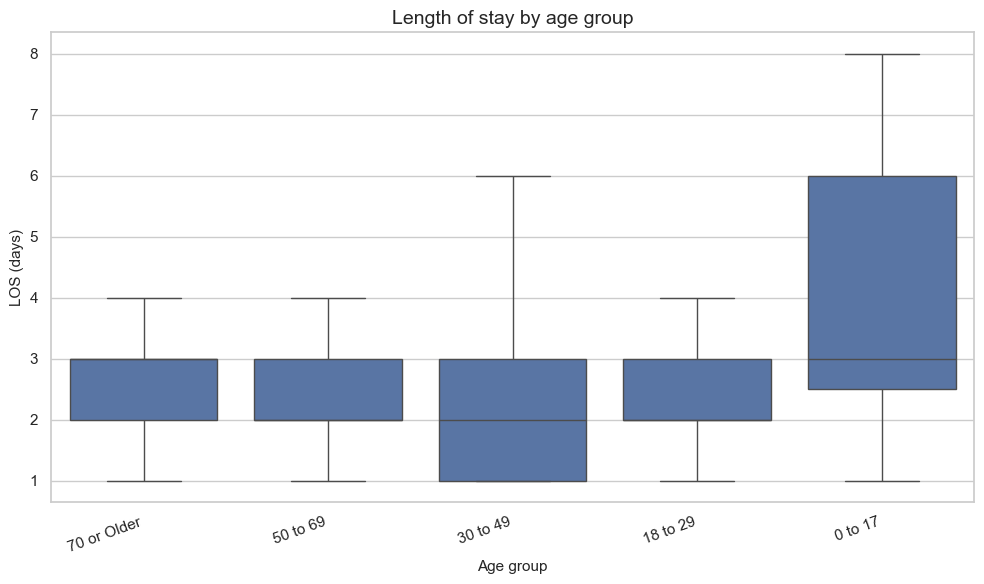

In [20]:
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=hip_cohort, x="age_group", y="length_of_stay", showfliers=False, color="C0")
ax.set(title="Length of stay by age group", xlabel="Age group", ylabel="LOS (days)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

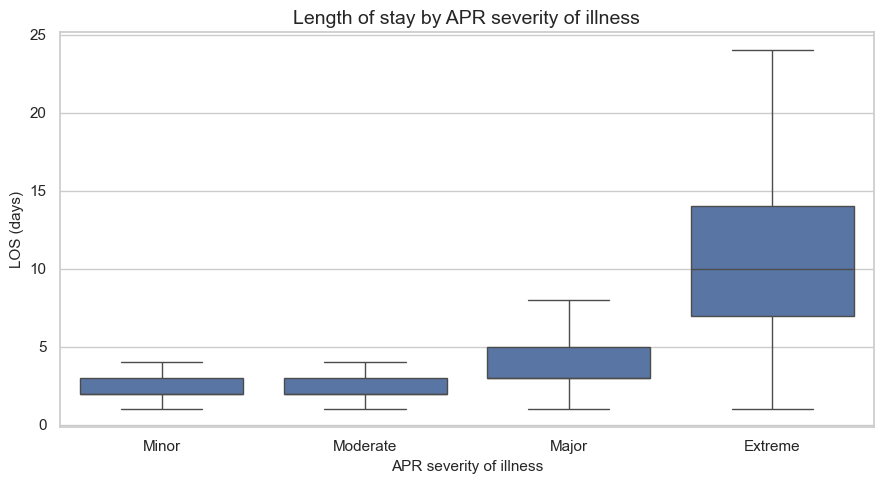

In [21]:
severity_order = ["Minor", "Moderate", "Major", "Extreme"]
present_severity = [x for x in severity_order if x in hip_cohort["apr_severity_of_illness_description"].unique()]
plt.figure(figsize=(9, 5))
ax = sns.boxplot(data=hip_cohort, x="apr_severity_of_illness_description",
                 y="length_of_stay", order=present_severity, showfliers=False, color="C0")
ax.set(title="Length of stay by APR severity of illness", xlabel="APR severity of illness", ylabel="LOS (days)")
plt.tight_layout()
plt.show()

## Hospital cost and charge analysis

In [22]:
financial_summary = hip_cohort[["total_charges", "total_costs", "cost_to_charge_ratio"]].describe(
    percentiles=[.25, .5, .75, .90, .95, .99]
).T
display(financial_summary)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_charges,"26,286.00","59,440.01","38,481.87",321.00,"32,225.89","51,717.00","71,779.07","106,452.61","126,958.70","181,898.50","1,420,121.06"
total_costs,"26,286.00","20,910.35","13,020.68",64.45,"13,611.72","18,588.72","24,070.15","31,424.81","40,632.07","65,635.19","688,280.05"
cost_to_charge_ratio,"26,286.00",0.39,0.15,0.14,0.30,0.36,0.43,0.53,0.65,0.84,2.68


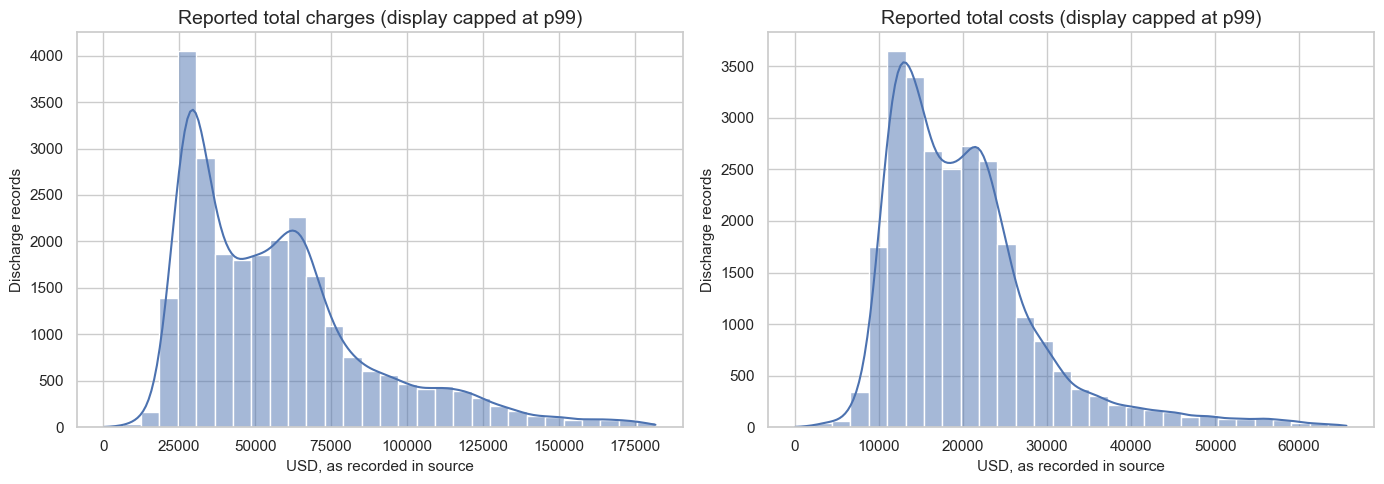

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [
    (axes[0], "total_charges", "Reported total charges"),
    (axes[1], "total_costs", "Reported total costs")
]:
    cap = hip_cohort[col].quantile(.99)
    sns.histplot(hip_cohort.loc[hip_cohort[col] <= cap, col], bins=30, kde=True, ax=ax, color="C0")
    ax.set_title(f"{title} (display capped at p99)")
    ax.set_xlabel("USD, as recorded in source")
    ax.set_ylabel("Discharge records")
plt.tight_layout()
plt.show()

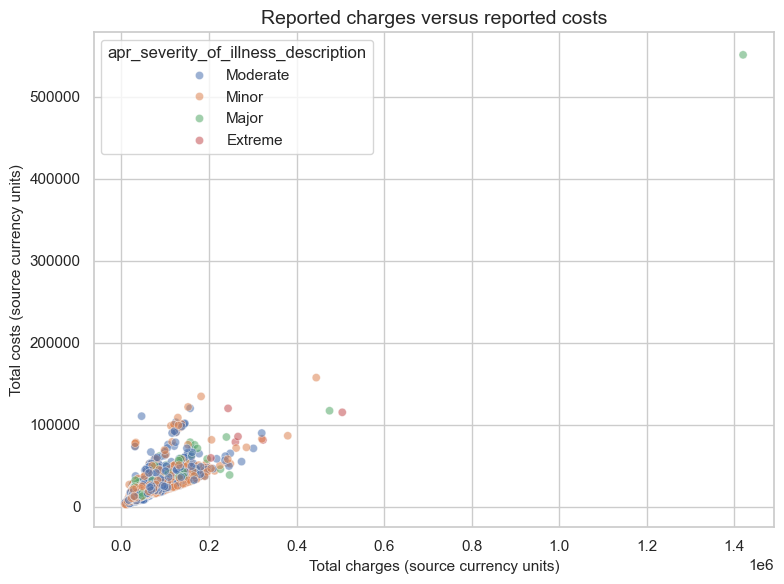

In [24]:
sample_for_scatter = hip_cohort.sample(min(5000, len(hip_cohort)), random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample_for_scatter, x="total_charges", y="total_costs",
                hue="apr_severity_of_illness_description", alpha=.55, s=35, palette="deep")
plt.title("Reported charges versus reported costs")
plt.xlabel("Total charges (source currency units)")
plt.ylabel("Total costs (source currency units)")
plt.tight_layout()
plt.show()

,apr_severity_of_illness_description,records,avg_cost,median_cost,avg_los
0,Extreme,74,"59,515.79","44,858.58",12.45
1,Major,1195,"27,578.21","22,342.31",4.58
3,Moderate,13282,"20,603.29","18,691.02",2.67
2,Minor,11735,"20,335.44","18,120.20",2.37


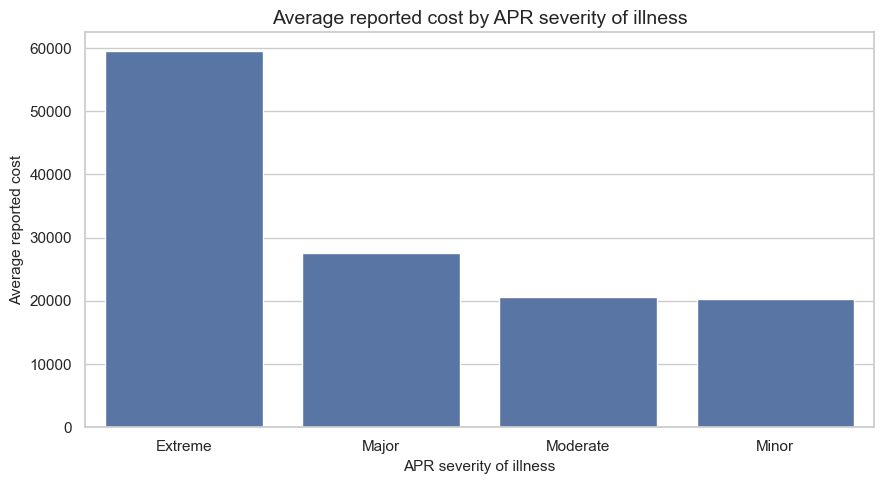

In [25]:
severity_cost = (
    hip_cohort.groupby("apr_severity_of_illness_description")
    .agg(records=("total_costs", "size"),
         avg_cost=("total_costs", "mean"),
         median_cost=("total_costs", "median"),
         avg_los=("length_of_stay", "mean"))
    .reset_index()
    .sort_values("avg_cost", ascending=False)
)
display(severity_cost.round(2))
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=severity_cost, x="apr_severity_of_illness_description", y="avg_cost", color="C0")
ax.set(title="Average reported cost by APR severity of illness",
       xlabel="APR severity of illness", ylabel="Average reported cost")
plt.tight_layout()
plt.show()

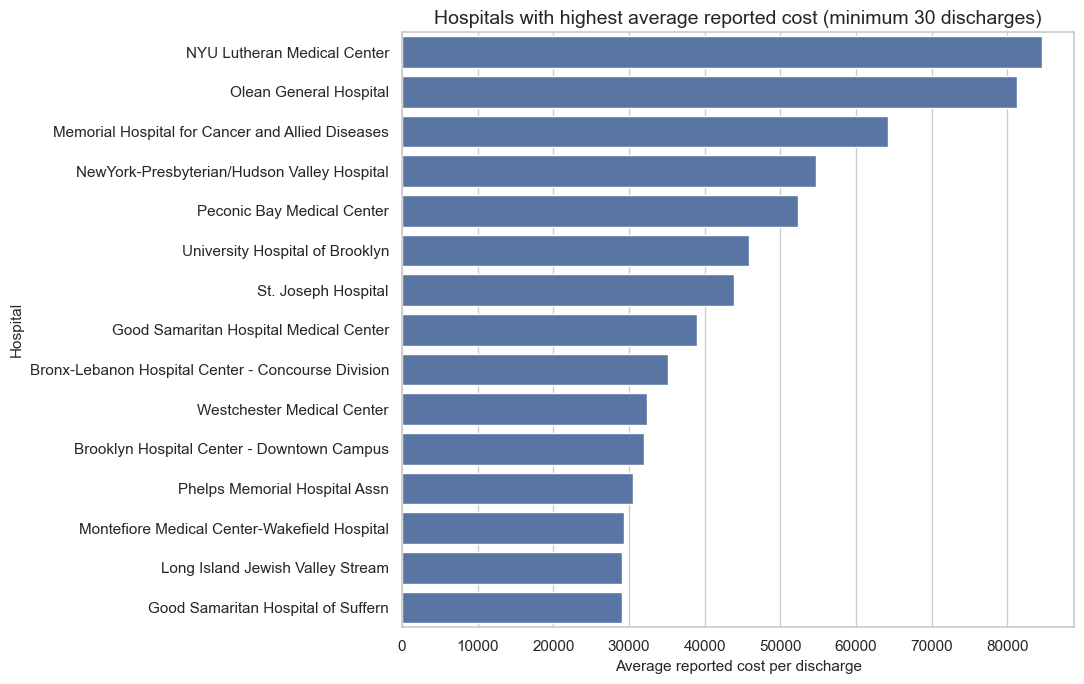

In [26]:
top_cost_hospitals = (
    hospital_metrics.query("discharges >= 30")
    .sort_values("avg_cost", ascending=False).head(15)
)
plt.figure(figsize=(11, 7))
ax = sns.barplot(data=top_cost_hospitals, y="facility_name", x="avg_cost", color="C0")
ax.set(title="Hospitals with highest average reported cost (minimum 30 discharges)",
       xlabel="Average reported cost per discharge", ylabel="Hospital")
plt.tight_layout()
plt.show()

## APR-DRG severity and risk of mortality

In [27]:
severity_risk = (
    hip_cohort.groupby(["apr_severity_of_illness_description", "apr_risk_of_mortality"])
    .agg(
        discharges=("facility_id", "size"),
        avg_los=("length_of_stay", "mean"),
        avg_cost=("total_costs", "mean"),
        avg_charges=("total_charges", "mean")
    ).reset_index()
)
display(severity_risk.round(2).sort_values("discharges", ascending=False))

,apr_severity_of_illness_description,apr_risk_of_mortality,discharges,avg_los,avg_cost,avg_charges
8,Minor,Minor,11205,2.33,"20,273.29","58,546.98"
12,Moderate,Minor,10814,2.54,"20,273.52","56,908.73"
13,Moderate,Moderate,2313,3.16,"21,825.07","61,891.83"
9,Minor,Moderate,510,3.16,"21,179.01","58,588.52"
6,Major,Moderate,475,4.51,"27,943.11","75,865.23"
5,Major,Minor,387,3.33,"22,855.09","65,106.19"
4,Major,Major,301,6.08,"32,200.69","89,636.22"
11,Moderate,Major,152,4.46,"25,378.82","72,282.84"
0,Extreme,Extreme,58,11.19,"54,184.98","161,187.00"
3,Major,Extreme,32,6.75,"35,801.90","109,649.73"


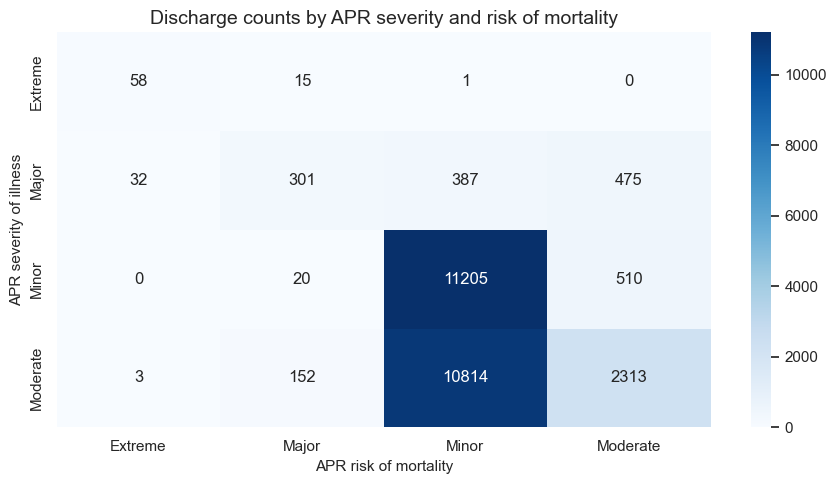

In [28]:

severity_risk_counts = (
    hip_cohort.groupby(["apr_severity_of_illness_description", "apr_risk_of_mortality"])
    .size().reset_index(name="records")
)
heat = severity_risk_counts.pivot(index="apr_severity_of_illness_description",
                                  columns="apr_risk_of_mortality", values="records").fillna(0)
plt.figure(figsize=(9, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues")
plt.title("Discharge counts by APR severity and risk of mortality")
plt.xlabel("APR risk of mortality")
plt.ylabel("APR severity of illness")
plt.tight_layout()
plt.show()

,apr_risk_of_mortality,records,avg_los
0,Extreme,93,9.54
1,Major,488,5.88
3,Moderate,3298,3.36
2,Minor,22407,2.45


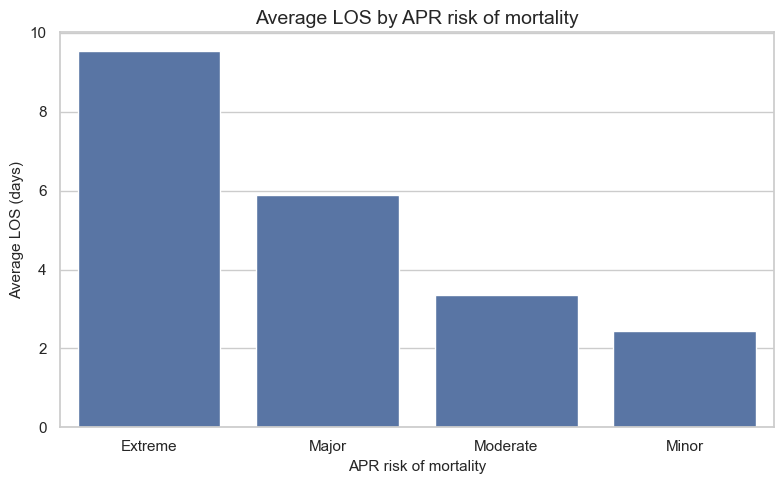

In [29]:

risk_los = (
    hip_cohort.groupby("apr_risk_of_mortality")
    .agg(records=("length_of_stay", "size"), avg_los=("length_of_stay", "mean"))
    .reset_index().sort_values("avg_los", ascending=False)
)
display(risk_los.round(2))
plt.figure(figsize=(8, 5))
sns.barplot(data=risk_los, x="apr_risk_of_mortality", y="avg_los", color="C0")
plt.title("Average LOS by APR risk of mortality")
plt.xlabel("APR risk of mortality")
plt.ylabel("Average LOS (days)")
plt.tight_layout()
plt.show()

## Discharge disposition and post-acute care

In [30]:
disposition_summary = (
    hip_cohort.groupby("patient_disposition")
    .agg(
        discharges=("facility_id", "size"),
        avg_los=("length_of_stay", "mean"),
        avg_cost=("total_costs", "mean")
    )
    .reset_index()
    .sort_values("discharges", ascending=False)
)
disposition_summary["share_pct"] = disposition_summary["discharges"] / len(hip_cohort) * 100
display(disposition_summary.round(2))

,patient_disposition,discharges,avg_los,avg_cost,share_pct
7,Home w/ Home Health Services,14459,2.36,"20,499.98",55.01
6,Home or Self Care,5388,2.20,"17,795.04",20.50
16,Skilled Nursing Home,5072,3.63,"23,657.92",19.30
10,Inpatient Rehabilitation Facility,1161,3.84,"27,320.02",4.42
15,Short-term Hospital,77,3.30,"24,204.10",0.29
8,Hosp Basd Medicare Approved Swing Bed,32,3.81,"25,139.14",0.12
2,Court/Law Enforcement,25,3.60,"18,379.37",0.10
3,Expired,20,8.90,"57,708.11",0.08
0,Another Type Not Listed,12,5.42,"26,282.91",0.05
11,Left Against Medical Advice,12,2.50,"24,799.64",0.05


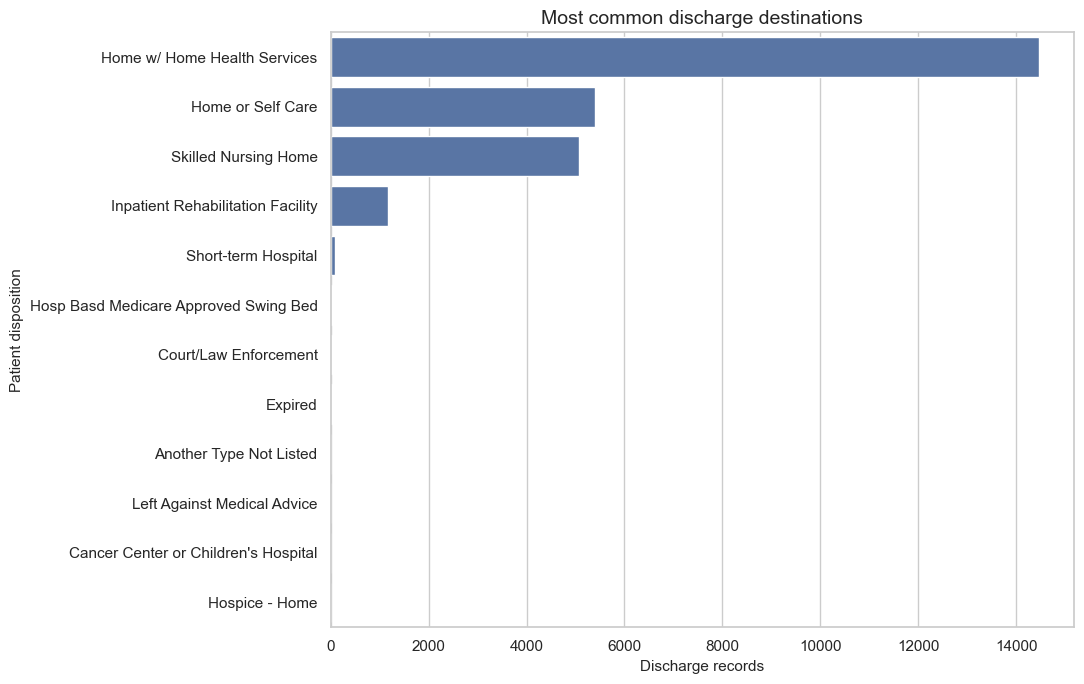

In [31]:

top_dispositions = disposition_summary.head(12)
plt.figure(figsize=(11, 7))
sns.barplot(data=top_dispositions, y="patient_disposition", x="discharges", color="C0")
plt.title("Most common discharge destinations")
plt.xlabel("Discharge records")
plt.ylabel("Patient disposition")
plt.tight_layout()
plt.show()

In [32]:

facility_care_values = [
    "Skilled Nursing Home",
    "Inpatient Rehabilitation Facility",
    "Hosp Basd Medicare Approved Swing Bed",
    "Medicare Cert Long Term Care Hospital",
    "Medicaid Cert Nursing Facility",
    "Facility w/ Custodial/Supportive Care"
]

def map_discharge_setting(value):
    if value == "Home or Self Care":
        return "Home or self care"
    if value == "Home w/ Home Health Services":
        return "Home with home health"
    if value in facility_care_values:
        return "Post-acute facility care"
    return "Other disposition"

hip_cohort["discharge_setting"] = hip_cohort["patient_disposition"].map(map_discharge_setting)
setting_summary = (
    hip_cohort.groupby("discharge_setting")
    .agg(discharges=("facility_id", "size"),
         avg_los=("length_of_stay", "mean"),
         avg_cost=("total_costs", "mean"))
    .reset_index()
)
setting_summary["share_pct"] = setting_summary["discharges"] / len(hip_cohort) * 100
display(setting_summary.round(2))

,discharge_setting,discharges,avg_los,avg_cost,share_pct
0,Home or self care,5388,2.20,"17,795.04",20.50
1,Home with home health,14459,2.36,"20,499.98",55.01
2,Other disposition,166,4.16,"27,692.24",0.63
3,Post-acute facility care,6273,3.67,"24,352.56",23.86


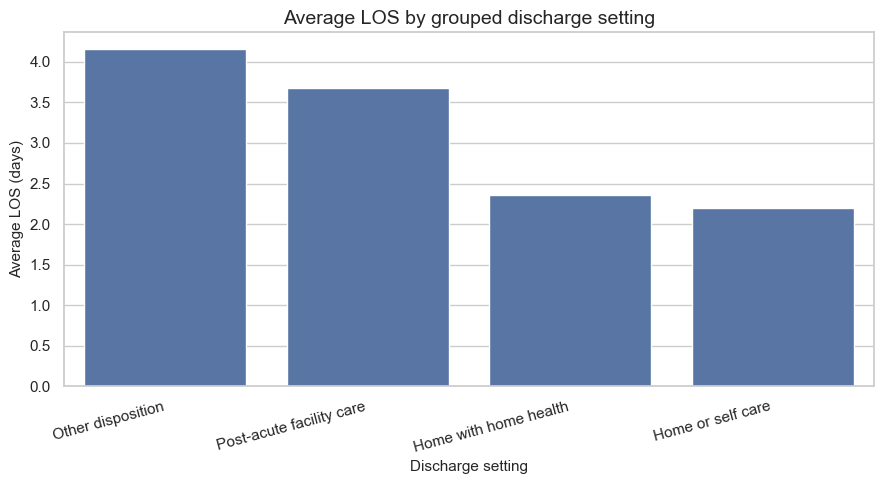

In [33]:

plt.figure(figsize=(9, 5))
sns.barplot(data=setting_summary.sort_values("avg_los", ascending=False),
            x="discharge_setting", y="avg_los", color="C0")
plt.title("Average LOS by grouped discharge setting")
plt.xlabel("Discharge setting")
plt.ylabel("Average LOS (days)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Provider and hospital operations

In [34]:
provider_volume = (
    hip_cohort.groupby("operating_provider_license_number")
    .agg(
        discharges=("facility_id", "size"),
        hospitals=("facility_id", "nunique"),
        avg_los=("length_of_stay", "mean"),
        avg_cost=("total_costs", "mean")
    )
    .reset_index()
    .sort_values("discharges", ascending=False)
)
display(provider_volume.head(20).round(2))

,operating_provider_license_number,discharges,hospitals,avg_los,avg_cost
336,210947,518,1,1.91,"21,454.82"
414,233551,424,1,1.21,"22,234.72"
395,229062,380,2,2.72,"13,993.69"
342,211832,331,1,1.47,"12,249.50"
307,204330,309,1,1.93,"10,485.16"
537,266159,295,2,1.94,"13,685.76"
489,253920,289,1,2.53,"24,251.54"
175,171009,283,1,1.81,"12,231.37"
447,244799,282,2,1.85,"15,979.63"
427,236982,267,1,2.80,"22,370.50"


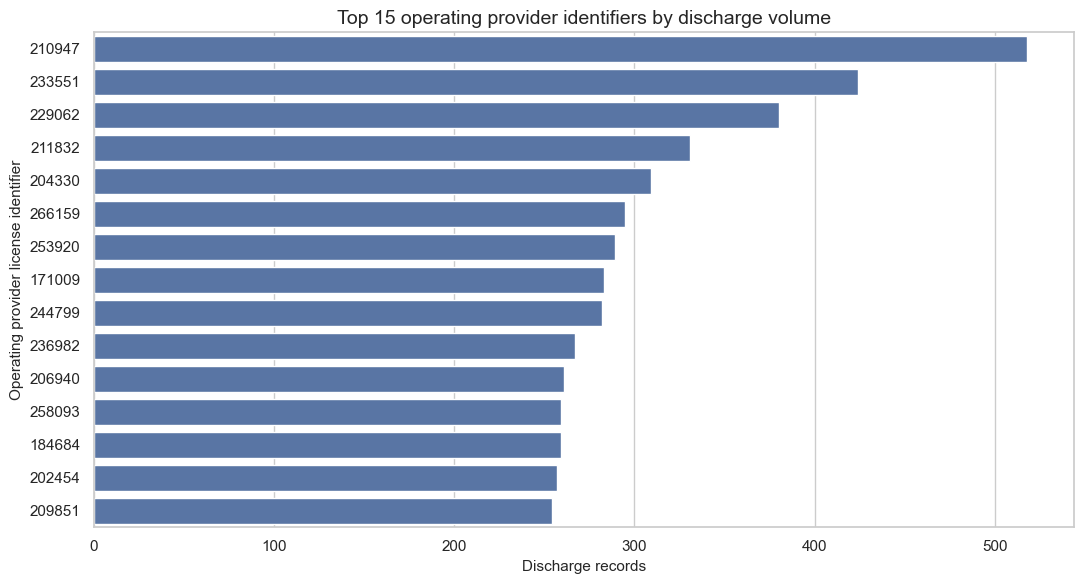

In [35]:

top_providers = provider_volume.head(15).copy()
top_providers["provider_id"] = top_providers["operating_provider_license_number"].astype(str)
plt.figure(figsize=(11, 6))
sns.barplot(data=top_providers, y="provider_id", x="discharges", color="C0")
plt.title("Top 15 operating provider identifiers by discharge volume")
plt.xlabel("Discharge records")
plt.ylabel("Operating provider license identifier")
plt.tight_layout()
plt.show()

## Advanced analysis: hospital benchmarking and outlier screening

In [36]:

MIN_HOSPITAL_VOLUME = 30
eligible_hospitals = hospital_metrics.query("discharges >= @MIN_HOSPITAL_VOLUME").copy()

overall_avg_los = hip_cohort["length_of_stay"].mean()
overall_avg_cost = hip_cohort["total_costs"].mean()

eligible_hospitals["los_variance_vs_cohort"] = eligible_hospitals["avg_los"] - overall_avg_los
eligible_hospitals["cost_variance_vs_cohort"] = eligible_hospitals["avg_cost"] - overall_avg_cost

display(eligible_hospitals[[
    "facility_id", "facility_name", "hospital_county", "discharges",
    "avg_los", "los_variance_vs_cohort", "avg_cost", "cost_variance_vs_cohort"
]].sort_values("cost_variance_vs_cohort", ascending=False).head(20).round(2))

,facility_id,facility_name,hospital_county,discharges,avg_los,los_variance_vs_cohort,avg_cost,cost_variance_vs_cohort
116,1304,NYU Lutheran Medical Center,Kings,124,2.61,-0.04,"84,601.41","63,691.06"
6,66,Olean General Hospital,Cattaraugus,38,2.55,-0.10,"81,265.28","60,354.93"
130,1453,Memorial Hospital for Cancer and Allied Diseases,Manhattan,51,9.10,6.45,"64,235.67","43,325.32"
94,1039,NewYork-Presbyterian/Hudson Valley Hospital,Westchester,121,3.21,0.56,"54,719.29","33,808.94"
87,938,Peconic Bay Medical Center,Suffolk,342,2.67,0.02,"52,369.44","31,459.09"
121,1320,University Hospital of Brooklyn,Kings,52,4.46,1.81,"45,906.69","24,996.34"
46,551,St. Joseph Hospital,Nassau,38,3.05,0.40,"43,905.84","22,995.49"
86,925,Good Samaritan Hospital Medical Center,Suffolk,63,2.79,0.14,"39,024.73","18,114.38"
111,1178,Bronx-Lebanon Hospital Center - Concourse Divi...,Bronx,47,2.53,-0.12,"35,218.42","14,308.07"
104,1139,Westchester Medical Center,Westchester,52,4.69,2.04,"32,406.20","11,495.85"


In [37]:
los_p95 = hip_cohort["length_of_stay"].quantile(.95)
cost_p95 = hip_cohort["total_costs"].quantile(.95)
charge_p95 = hip_cohort["total_charges"].quantile(.95)

outlier_summary = pd.DataFrame({
    "measure": ["LOS", "Reported costs", "Reported charges"],
    "p95_threshold": [los_p95, cost_p95, charge_p95],
    "records_above_p95": [
        (hip_cohort["length_of_stay"] > los_p95).sum(),
        (hip_cohort["total_costs"] > cost_p95).sum(),
        (hip_cohort["total_charges"] > charge_p95).sum()
    ]
})
display(outlier_summary.round(2))

,measure,p95_threshold,records_above_p95
0,LOS,5.00,1183
1,Reported costs,"40,632.07",1315
2,Reported charges,"126,958.70",1315


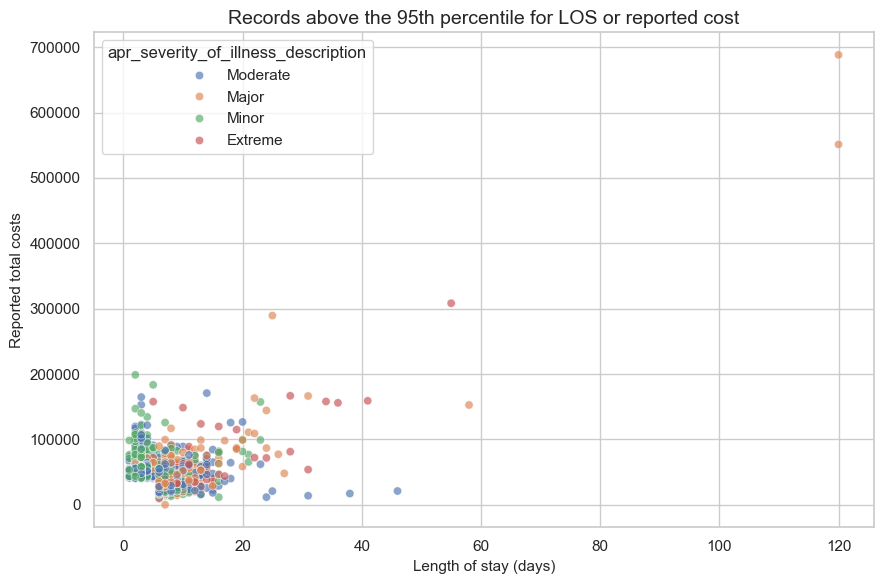

,facility_name,hospital_county,age_group,length_of_stay,apr_severity_of_illness_description,apr_risk_of_mortality,total_charges,total_costs,patient_disposition
13639,Kings County Hospital Center,Kings,30 to 49,120,Major,Moderate,"1,239,742.16","688,280.05",Home or Self Care
16699,Hospital for Special Surgery,Manhattan,50 to 69,120,Major,Major,"1,420,121.06","551,241.21",Skilled Nursing Home
14782,NYU Hospital for Joint Diseases,Manhattan,50 to 69,55,Extreme,Major,"877,501.61","308,346.25",Skilled Nursing Home
22065,New York Presbyterian Hospital - Columbia Pres...,Manhattan,50 to 69,25,Major,Major,"625,648.98","289,451.94",Home w/ Home Health Services
13755,NYU Lutheran Medical Center,Kings,50 to 69,2,Minor,Minor,"223,554.83","198,778.22",Inpatient Rehabilitation Facility


In [38]:

outlier_records = hip_cohort.loc[
    (hip_cohort["length_of_stay"] > los_p95) |
    (hip_cohort["total_costs"] > cost_p95)
].copy()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=outlier_records, x="length_of_stay", y="total_costs",
                hue="apr_severity_of_illness_description", alpha=.65, palette="deep")
plt.title("Records above the 95th percentile for LOS or reported cost")
plt.xlabel("Length of stay (days)")
plt.ylabel("Reported total costs")
plt.tight_layout()
plt.show()

display(outlier_records[[
    "facility_name", "hospital_county", "age_group", "length_of_stay",
    "apr_severity_of_illness_description", "apr_risk_of_mortality",
    "total_charges", "total_costs", "patient_disposition"
]].sort_values("total_costs", ascending=False).head())

## Statistical association: exploratory, not causal

In [39]:
if SCIPY_AVAILABLE:
    rho, p_value = stats.spearmanr(
        hip_cohort["length_of_stay"],
        hip_cohort["total_costs"],
        nan_policy="omit"
    )
    print(f"Spearman correlation (LOS vs reported costs): {rho:.3f}")
    print(f"P-value: {p_value:.4g}")
else:
    print("SciPy is not installed. Install it with: pip install scipy")

Spearman correlation (LOS vs reported costs): 0.393
P-value: 0


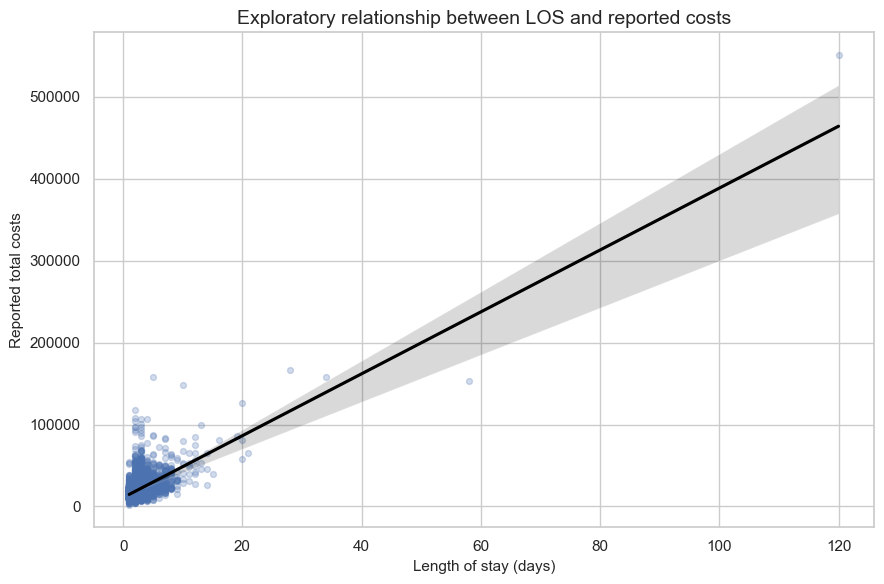

In [40]:

plt.figure(figsize=(9, 6))
sns.regplot(
    data=hip_cohort.sample(min(5000, len(hip_cohort)), random_state=7),
    x="length_of_stay", y="total_costs",
    scatter_kws={"alpha": .25, "s": 18},
    line_kws={"color": "black"}, color="C0"
)
plt.title("Exploratory relationship between LOS and reported costs")
plt.xlabel("Length of stay (days)")
plt.ylabel("Reported total costs")
plt.tight_layout()
plt.show()